Order of Events
1. Planning
    - Get coordinates of environment (from Vision)
    - Compute visibility graph and path (from Global Nav)
3. Motion
    - Start following path
    - Continuously correct route with Kalman filter (from Kalman)
4. Local Navigation
    - Add extra obstacle in path
    - Avoid obstacle (from Local Nav)
5. Success
    - Reach Goal

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from tdmclient import ClientAsync, aw
import math
from VisibilityGraph import *
from kalman_filter import *
from Vision import *

In [2]:
client = ClientAsync()
node = aw(client.wait_for_node())
await node.lock()

Node eeecc8f0-055d-414f-a168-42c3ba3a5cd9

In [3]:
# UNCOMMENT TO TEST HARDCODED MAP

# Global Nav Variables as standin for input from Vision
# ob1 = [(176, 206), (215, 217), (194, 294), (155, 283)]
# ob2 = [(522, 440), (562, 440), (562, 520), (522, 520)]
# ob3 = [(870, 267), (909, 256), (930, 333), (891, 344)]

# raw_obstacles = (ob1, ob2, ob3)

In [3]:
def wrap_angle(angle):
    """Wrap angle to [-pi, pi]."""
    return math.atan2(math.sin(angle), math.cos(angle))

def compute_heading(a, b, prev_heading):
    dx = b[0] - a[0]
    dy = b[1] - a[1]

    distance = math.hypot(dx, dy)
    abs_heading = math.atan2(dy, dx)          # absolute heading of this segment
    turn = wrap_angle(abs_heading - prev_heading)  # signed turn needed from current heading

    return distance, turn, abs_heading

In [4]:
SPEED_TO_MM_S = 0.335   
WHEEL_BASE = 95.0

async def set_speed(left, right):
    await node.set_variables({
        "motor.left.target": [int(left)],
        "motor.right.target": [int(right)]
    })
    
async def forward(v, d): # [mm/s, mm]
    T = d/v
    thymio_v = v/SPEED_TO_MM_S
    
    try:
        await set_speed(thymio_v, thymio_v)
        await client.sleep(T)          
    finally:
        await set_speed(0, 0)
        
async def turn(v, theta): # [rad/s, rad]

    arc = abs(theta) * WHEEL_BASE / 2 
    T = arc / v                          
    thymio_v =  abs(v) / SPEED_TO_MM_S         
    direction = 1 if theta > 0 else -1
    try:
        await set_speed(-direction * thymio_v, direction * thymio_v)
        await client.sleep(T)
    finally:
        await set_speed(0, 0)

Automatic threshold: 150
Obstacles detected: 0


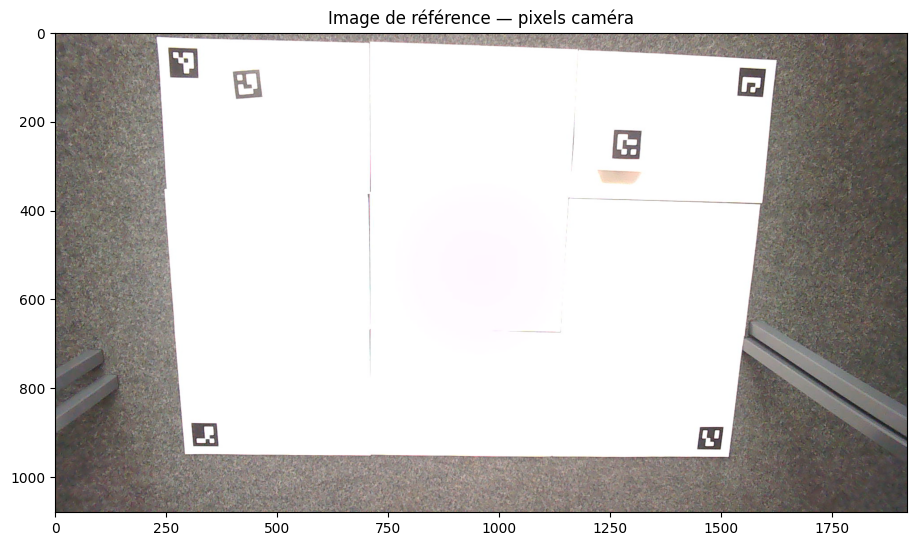

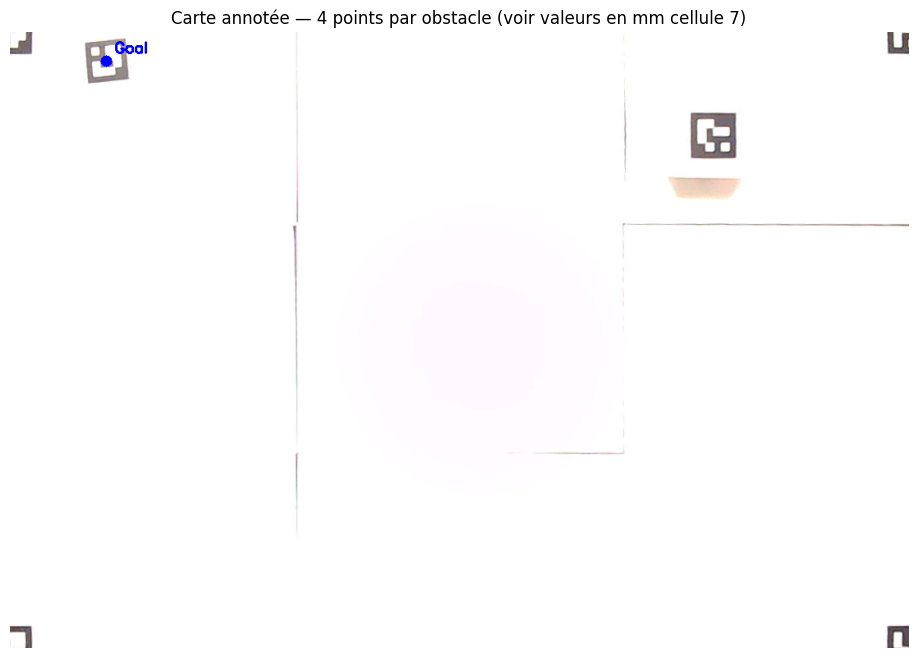

Image enregistrée : /Users/landelain/Desktop/cs/robotic_mobile/mobile_robotics/navigation_annotated.png


In [3]:
initialize_vision(True)

[0, 3, 4, 1] [array([131.93, 390.95]), array([308.14283087, 505.79173004]), array([666.99936682, 563.13770918]), array([946.77, 349.2 ])]
-0.53


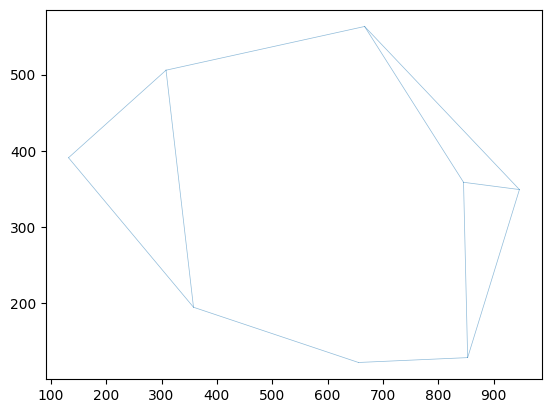

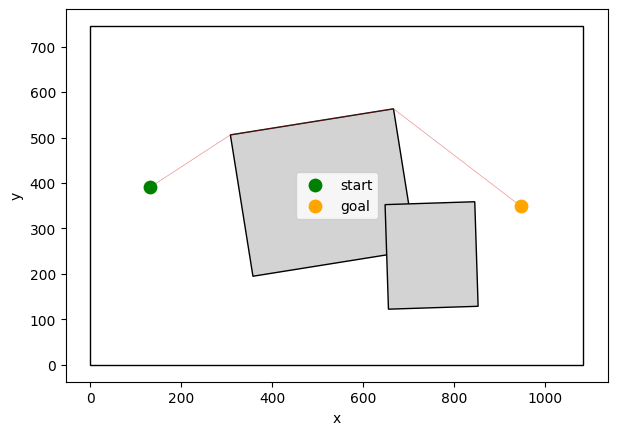

In [8]:
raw_obstacles = get_obstacles_pose()[1:]

start = tuple(get_current_thymio_pose()[:2])
goal = tuple(get_goal_pose())

path, coords = run_global_nav(start, goal, raw_obstacles)
print(path, coords)

v = 100
x = get_current_thymio_pose()[2:]
prev_heading = x[0]
print(prev_heading)

In [13]:
for i in range(len(path)-1):
    distance, heading, prev_heading = compute_heading(coords[i], coords[i+1], prev_heading)
    print(distance, heading, prev_heading)
    await turn(v, heading)
    await forward(v, distance)

210.3320820047631 1.2304210117491596 0.5775846197800968
363.40965138481926 -0.41912245665273673 0.15846216312736003
352.1944783751781 -0.8112985550964229 -0.6528363919690628


In [7]:
print(get_goal_pose())

[946.77, 349.2]


In [6]:
await node.unlock()

{'error_code': 2}

<br>
<br>
<br>

# testing kalman filter

<br>
<br>
<br>

In [6]:
await forward(20, 200)

Automatic threshold: 150
Obstacles detected: 0


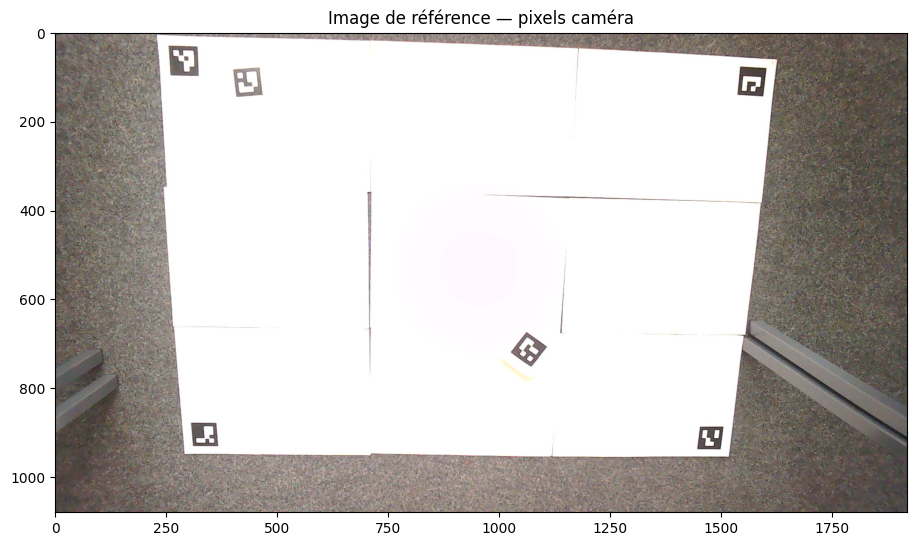

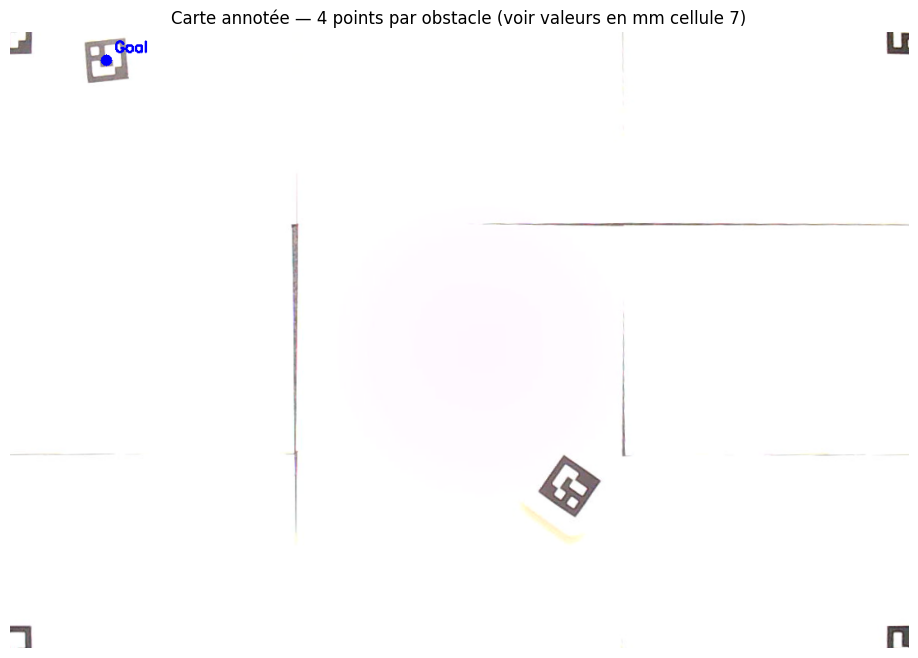

Image enregistrée : /Users/landelain/Desktop/cs/robotic_mobile/mobile_robotics/navigation_annotated.png


In [4]:
initialize_vision(True)

In [5]:
task = await start_kalman(client, node)

await forward(20, 2*200)

log = await stop_kalman(task)

In [8]:
await stop_kalman(task)

In [6]:
log

{'t': [0.4239619999999995,
  0.7414333749999997,
  1.0562030839999998,
  1.3722132090000017,
  1.6897163749999997,
  2.0046735840000025,
  2.318834292000002,
  2.6329061250000017,
  2.9565489590000027,
  3.2809224169999993,
  3.599858417,
  3.913028583999999,
  4.230990875,
  4.545541584000002,
  4.863994209000001,
  5.183621084000002,
  5.499298792000001,
  5.814868709000002,
  6.129898125,
  6.4395056250000025,
  6.753130667000001,
  7.072587334000001,
  7.389165834,
  7.70823425,
  8.021154167000002,
  8.333543834,
  8.649191834,
  8.966765167000002,
  9.280709167000001,
  9.599121750000002,
  9.912239125,
  10.230272500000002,
  10.546358042000001,
  10.863166125,
  11.178531625000002,
  11.497055250000003,
  11.811032709000003,
  12.125697042000002,
  12.442270209,
  12.757575084000003,
  13.072992375000002,
  13.388275375,
  13.706316959000002,
  14.016938167,
  14.331397917,
  14.649974792000002,
  14.962955209,
  15.282519999999998,
  15.596281083999997,
  15.908573375000003,
 

In [8]:
dts = np.diff(log["t"])
print(1/np.median(dts), "Hz", dts.max(), "s")

8.567692421075574 Hz 0.12162804199999755 s


In [9]:
import time, asyncio

t = time.perf_counter(); await client.sleep(0.01)
print("client.sleep :", time.perf_counter() - t)

t = time.perf_counter(); await asyncio.sleep(0.01)
print("asyncio.sleep:", time.perf_counter() - t)

t = time.perf_counter(); l, r = node.v.motor.left.speed, node.v.motor.right.speed
print("read speeds  :", time.perf_counter() - t)

client.sleep : 0.3539189589999978
asyncio.sleep: 0.01119754199999079
read speeds  : 0.00010749999998438398
